# ARTI 502 Final Project: CNN Model 1 (ResNet18)


## 1. Setup and configuration

In [1]:
import os, json, random, time, zipfile, subprocess, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from PIL import Image
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve,
                             confusion_matrix)

# ---------------- Hyperparameters (the values Member 5 may tune) ----------------
CFG = dict(
    seed=42,
    image_size=224,
    batch_size=64,
    epochs=15,
    lr=1e-4,
    weight_decay=1e-4,
    pretrained=True,         # ImageNet weights
    imbalance="pos_weight",
    augment_flip=True,
    select_metric="ap",
    patience=4,
    num_workers=2,
)

# ---------------- Paths ----------------
SPLIT_DIR = Path("/content/NIH_Dataset_Handoff")   # holds train/validation/test_metadata.csv
IMAGE_DIR = Path("/content/images_224")            # full 224x224 images are downloaded here
OUT_DIR   = Path("/content/resnet18_outputs")      # checkpoints, predictions, figures
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Numbers from Member 1's split_summary.csv: (images, patients, pneumonia images)
EXPECTED = {
    "train":      (78921, 21563, 952),
    "validation": (16825, 4621, 208),
    "test":       (16374, 4621, 193),
}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", device, "| torch", torch.__version__)
if device.type == "cpu":
    print("WARNING: no GPU. In Colab use Runtime > Change runtime type > GPU before training.")

Device: cuda | torch 2.14.1+cu130


## 2. Get split files


In [2]:
zip_in = Path("/content/NIH_Dataset_Handoff.zip")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_in) as z:
    z.extractall(SPLIT_DIR)
found = list(SPLIT_DIR.rglob("train_metadata.csv"))
assert found, "train_metadata.csv not found"
SPLIT_DIR = found[0].parent
print(sorted(p.name for p in SPLIT_DIR.glob("*.csv")))

['NIH_ChestXray14_Metadata_Cleaned.csv', 'age_statistics.csv', 'label_frequencies.csv', 'metadata_cleaned.csv', 'sample_metadata.csv', 'split_summary.csv', 'test_metadata.csv', 'train_metadata.csv', 'validation_metadata.csv']


## 3. Download the full 224 px images


In [3]:
subprocess.run(["pip", "-q", "install", "awscli"], check=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

r = subprocess.run(
    ["aws", "s3", "sync", "s3://nih-chest-x-rays/images_224x224/", str(IMAGE_DIR),
     "--no-sign-request", "--region", "us-east-2", "--only-show-errors"],
    capture_output=True, text=True)
print("return code:", r.returncode)
print(r.stderr[-1500:])
print("PNG files on disk:", sum(1 for _ in IMAGE_DIR.rglob("*.png")))

return code: 0

PNG files on disk: 112120


## 4. Load the splits and verify them
The checks below stop the run if anything differs from Member 1's numbers, if any patient appears in two splits, or if any image is missing from disk. Member 1's `create_data_loader` silently drops missing images, which would make my test set differ from Member 4's, so this notebook does not do that.

In [4]:
splits = {
    "train":      pd.read_csv(SPLIT_DIR / "train_metadata.csv"),
    "validation": pd.read_csv(SPLIT_DIR / "validation_metadata.csv"),
    "test":       pd.read_csv(SPLIT_DIR / "test_metadata.csv"),
}

# 1) same sizes and pneumonia counts as Member 1's summary
for name, d in splits.items():
    if name in EXPECTED:
        got = (len(d), d["Patient ID"].nunique(), int(d["Pneumonia"].sum()))
        assert got == EXPECTED[name], f"{name}: expected {EXPECTED[name]}, got {got}"

# 2) no patient in more than one split
ids = {n: set(d["Patient ID"]) for n, d in splits.items()}
assert ids["train"].isdisjoint(ids["validation"])
assert ids["train"].isdisjoint(ids["test"])
assert ids["validation"].isdisjoint(ids["test"])

# 3) every image exists on disk
def build_image_lookup(image_directory):
    return {p.name: str(p) for p in Path(image_directory).rglob("*.png")}

image_lookup = build_image_lookup(IMAGE_DIR)
for name, d in splits.items():
    missing = int((~d["Image Index"].isin(image_lookup)).sum())
    assert missing == 0, f"{name}: {missing} images missing on disk"

summary = pd.DataFrame({
    n: {"images": len(d), "patients": d["Patient ID"].nunique(),
        "pneumonia": int(d["Pneumonia"].sum()),
        "rate_%": round(100 * d["Pneumonia"].mean(), 2)}
    for n, d in splits.items()}).T
print("All checks passed.")
display(summary) if "display" in globals() else print(summary)

All checks passed.
             images  patients  pneumonia  rate_%
train       78921.0   21563.0      952.0    1.21
validation  16825.0    4621.0      208.0    1.24
test        16374.0    4621.0      193.0    1.18


## 5. Transforms, Dataset and DataLoaders

In [5]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]
S = CFG["image_size"]

train_tfms = [transforms.Resize((S, S))]
if CFG["augment_flip"]:
    train_tfms.append(transforms.RandomHorizontalFlip(p=0.5))
train_tfms += [transforms.ToTensor(), transforms.Normalize(imagenet_mean, imagenet_std)]
train_transform = transforms.Compose(train_tfms)

eval_transform = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class NIHChestXrayDataset(Dataset):
    def __init__(self, metadata, image_lookup, transform=None):
        self.metadata = metadata.reset_index(drop=True)
        self.paths = [image_lookup[f] for f in self.metadata["Image Index"]]
        self.labels = self.metadata["Pneumonia"].astype("float32").values
        self.transform = transform

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.labels[idx], dtype=torch.float32)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

g = torch.Generator()
g.manual_seed(CFG["seed"])

def make_loader(df, transform, shuffle=False, sampler=None):
    return DataLoader(
        NIHChestXrayDataset(df, image_lookup, transform),
        batch_size=CFG["batch_size"],
        shuffle=shuffle if sampler is None else False,
        sampler=sampler,
        num_workers=CFG["num_workers"],
        pin_memory=(device.type == "cuda"),
        worker_init_fn=seed_worker,
        generator=g,
        persistent_workers=CFG["num_workers"] > 0,
    )

train_df = splits["train"].reset_index(drop=True)
val_df   = splits["validation"].reset_index(drop=True)
test_df  = splits["test"].reset_index(drop=True)

# ---- class imbalance handling ----
n_pos = int(train_df["Pneumonia"].sum())
n_neg = len(train_df) - n_pos
pos_weight = None
sampler = None
if CFG["imbalance"] == "pos_weight":
    pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32, device=device)
elif CFG["imbalance"] == "sampler":
    w = np.where(train_df["Pneumonia"].values == 1, 1.0 / n_pos, 1.0 / n_neg)
    sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                    num_samples=len(train_df), replacement=True, generator=g)
print(f"train positives={n_pos}, negatives={n_neg}, imbalance mode={CFG['imbalance']}",
      f"| pos_weight={None if pos_weight is None else round(pos_weight.item(), 1)}")

train_loader = make_loader(train_df, train_transform, shuffle=True, sampler=sampler)
val_loader   = make_loader(val_df, eval_transform)
test_loader  = make_loader(test_df, eval_transform)

x, y = next(iter(train_loader))
print("batch:", tuple(x.shape), "labels:", tuple(y.shape))

train positives=952, negatives=77969, imbalance mode=pos_weight | pos_weight=81.9
batch: (64, 3, 224, 224) labels: (64,)


## 6. Model: ResNet18
ImageNet-pretrained ResNet18 with the final layer replaced by a single output logit. The loss is `BCEWithLogitsLoss`, optionally with `pos_weight`.

In [6]:
def build_resnet18(pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m

model = build_resnet18(CFG["pretrained"]).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"ResNet18 parameters: {n_params:,}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

@torch.no_grad()
def predict(model, loader):
    """Returns sigmoid probabilities in the same row order as the loader's dataframe."""
    model.eval()
    out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x).squeeze(1)
        out.append(torch.sigmoid(logits.float()).cpu())
    return torch.cat(out).numpy()

def val_scores(y_true, y_prob):
    return {"auroc": roc_auc_score(y_true, y_prob),
            "ap": average_precision_score(y_true, y_prob)}

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 22.0MB/s]


ResNet18 parameters: 11,177,025


## 7. Training
Each epoch trains on the training split and scores the validation split. The checkpoint with the best validation metric (`select_metric`) is kept, and training stops early after `patience` epochs without improvement.

In [7]:
y_val = val_df["Pneumonia"].values.astype(int)
history, best_score, best_epoch, wait = [], -1.0, -1, 0
ckpt_path = OUT_DIR / "resnet18_best.pt"

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    model.train()
    running, seen = 0.0, 0
    for x, y in train_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x).squeeze(1)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * x.size(0)
        seen += x.size(0)
    scheduler.step()

    sc = val_scores(y_val, predict(model, val_loader))
    row = {"epoch": epoch, "train_loss": running / seen, "val_auroc": sc["auroc"],
           "val_ap": sc["ap"], "lr": optimizer.param_groups[0]["lr"],
           "seconds": round(time.time() - t0, 1)}
    history.append(row)
    print(f"epoch {epoch:02d} | loss {row['train_loss']:.4f} | val AUROC {sc['auroc']:.4f} "
          f"| val AP {sc['ap']:.4f} | {row['seconds']}s")

    current = sc[CFG["select_metric"]]
    if current > best_score:
        best_score, best_epoch, wait = current, epoch, 0
        torch.save({"model": model.state_dict(), "epoch": epoch, "cfg": CFG}, ckpt_path)
    else:
        wait += 1
        if wait >= CFG["patience"]:
            print(f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}")
            break

hist = pd.DataFrame(history)
hist.to_csv(OUT_DIR / "training_history.csv", index=False)
print(f"Best epoch {best_epoch} ({CFG['select_metric']} = {best_score:.4f})")

epoch 01 | loss 1.3439 | val AUROC 0.6563 | val AP 0.0223 | 254.4s
epoch 02 | loss 1.2386 | val AUROC 0.6653 | val AP 0.0255 | 239.2s
epoch 03 | loss 1.2063 | val AUROC 0.7015 | val AP 0.0280 | 241.4s
epoch 04 | loss 1.1271 | val AUROC 0.6982 | val AP 0.0388 | 242.0s
epoch 05 | loss 1.0320 | val AUROC 0.7166 | val AP 0.0292 | 243.0s
epoch 06 | loss 0.8663 | val AUROC 0.7183 | val AP 0.0280 | 241.3s
epoch 07 | loss 0.7110 | val AUROC 0.7012 | val AP 0.0350 | 240.6s
epoch 08 | loss 0.5001 | val AUROC 0.7045 | val AP 0.0273 | 242.6s
Early stopping at epoch 8. Best epoch: 4
Best epoch 4 (ap = 0.0388)


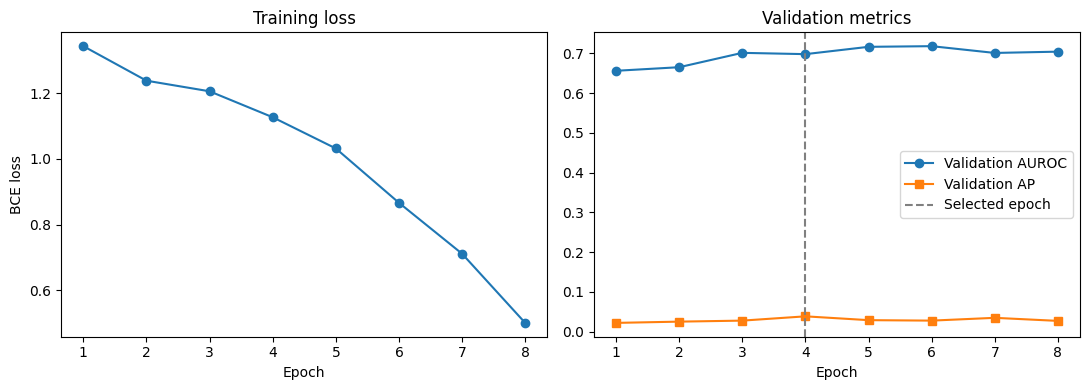

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["epoch"], hist["train_loss"], marker="o")
ax[0].set(title="Training loss", xlabel="Epoch", ylabel="BCE loss")
ax[1].plot(hist["epoch"], hist["val_auroc"], marker="o", label="Validation AUROC")
ax[1].plot(hist["epoch"], hist["val_ap"], marker="s", label="Validation AP")
ax[1].axvline(best_epoch, color="gray", ls="--", label="Selected epoch")
ax[1].set(title="Validation metrics", xlabel="Epoch")
ax[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=200)
plt.show()

## 8. Choose the decision threshold (validation set only)


In [9]:
ckpt = torch.load(ckpt_path, map_location=device)
model.load_state_dict(ckpt["model"])
val_prob = predict(model, val_loader)

prec, rec, thr = precision_recall_curve(y_val, val_prob)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_i = int(np.argmax(f1))
THRESHOLD = float(thr[best_i])
print(f"Chosen threshold: {THRESHOLD:.4f}  (validation F1={f1[best_i]:.3f}, "
      f"precision={prec[best_i]:.3f}, recall={rec[best_i]:.3f})")

Chosen threshold: 0.7549  (validation F1=0.076, precision=0.047, recall=0.202)


## 9. Final evaluation on the test set


auroc                     0.678924
ap                        0.023349
threshold                 0.754915
precision                 0.022504
recall_sensitivity        0.082902
specificity               0.957048
f1                        0.035398
accuracy                  0.946745
tp                       16.000000
fp                      695.000000
tn                    15486.000000
fn                      177.000000
Baseline AP (prevalence): 0.0118


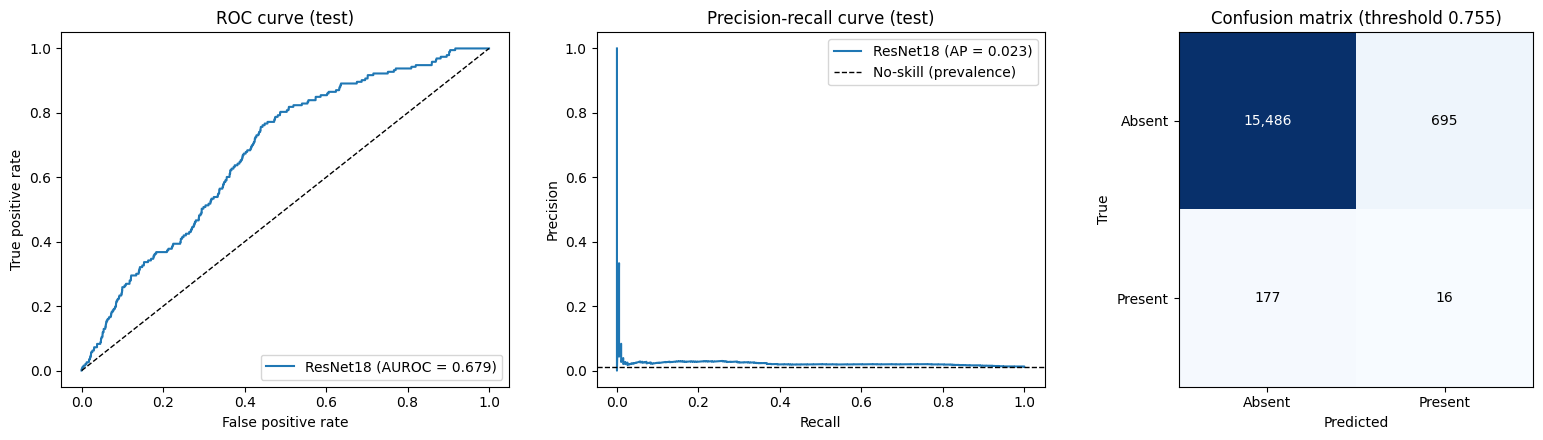

Saved predictions for validation and test.


In [10]:
y_test = test_df["Pneumonia"].values.astype(int)
test_prob = predict(model, test_loader)

def metrics_at(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec_ = tp / (tp + fp) if tp + fp else 0.0
    rec_ = tp / (tp + fn) if tp + fn else 0.0
    return {"auroc": roc_auc_score(y, p), "ap": average_precision_score(y, p),
            "threshold": thr, "precision": prec_, "recall_sensitivity": rec_,
            "specificity": tn / (tn + fp), "f1": (2 * prec_ * rec_ / (prec_ + rec_)) if prec_ + rec_ else 0.0,
            "accuracy": (tp + tn) / len(y), "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}

test_metrics = metrics_at(y_test, test_prob, THRESHOLD)
print(pd.Series(test_metrics).to_string())
print("Baseline AP (prevalence):", round(y_test.mean(), 4))

# ---- figures ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[0].plot(fpr, tpr, label=f"ResNet18 (AUROC = {test_metrics['auroc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(loc="lower right")

p_, r_, _ = precision_recall_curve(y_test, test_prob)
ax[1].plot(r_, p_, label=f"ResNet18 (AP = {test_metrics['ap']:.3f})")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="No-skill (prevalence)")
ax[1].set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")
ax[1].legend()

cm = confusion_matrix(y_test, (test_prob >= THRESHOLD).astype(int), labels=[0, 1])
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[2].set(title=f"Confusion matrix (threshold {THRESHOLD:.3f})", xlabel="Predicted", ylabel="True",
          xticks=[0, 1], yticks=[0, 1], xticklabels=["Absent", "Present"], yticklabels=["Absent", "Present"])
plt.tight_layout()
plt.savefig(OUT_DIR / "test_roc_pr_confusion.png", dpi=200)
plt.show()

# ---- save predictions for the ensemble (Member 5) ----
def pred_frame(df, prob, split):
    return pd.DataFrame({"Image Index": df["Image Index"], "Patient ID": df["Patient ID"],
                         "split": split, "y_true": df["Pneumonia"].astype(int), "y_prob": prob})

pd.concat([pred_frame(val_df, val_prob, "validation"),
           pred_frame(test_df, test_prob, "test")]).to_csv(OUT_DIR / "resnet18_predictions.csv", index=False)
print("Saved predictions for validation and test.")

## 10. Uncertainty: patient-level bootstrap confidence intervals


In [11]:
def cluster_bootstrap(df, y, p, thr, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    groups = list(df.reset_index(drop=True).groupby("Patient ID").indices.values())
    rows = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        idx = np.concatenate([groups[i] for i in pick])
        yy, pp = y[idx], p[idx]
        if yy.sum() == 0 or yy.sum() == len(yy):
            continue
        pred = pp >= thr
        tp = int(((pred == 1) & (yy == 1)).sum()); fp = int(((pred == 1) & (yy == 0)).sum())
        fn = int(((pred == 0) & (yy == 1)).sum())
        pr = tp / (tp + fp) if tp + fp else 0.0
        rc = tp / (tp + fn) if tp + fn else 0.0
        rows.append({"auroc": roc_auc_score(yy, pp), "ap": average_precision_score(yy, pp),
                     "precision": pr, "recall": rc,
                     "f1": 2 * pr * rc / (pr + rc) if pr + rc else 0.0})
    b = pd.DataFrame(rows)
    return b.quantile([0.025, 0.975]).T.rename(columns={0.025: "ci_low", 0.975: "ci_high"})

ci = cluster_bootstrap(test_df, y_test, test_prob, THRESHOLD)
ci.insert(0, "point_estimate", [test_metrics["auroc"], test_metrics["ap"],
                                test_metrics["precision"], test_metrics["recall_sensitivity"], test_metrics["f1"]])
ci.round(4).to_csv(OUT_DIR / "test_bootstrap_ci.csv")
display(ci.round(4)) if "display" in globals() else print(ci.round(4))

           point_estimate  ci_low  ci_high
auroc              0.6789  0.6425   0.7162
ap                 0.0233  0.0173   0.0383
precision          0.0225  0.0109   0.0359
recall             0.0829  0.0392   0.1306
f1                 0.0354  0.0171   0.0554


## 11. Error analysis by subgroup (test set)


In [12]:
ana = test_df.copy()
ana["y_prob"] = test_prob
ana["y_true"] = y_test
ana["pred"] = (test_prob >= THRESHOLD).astype(int)
ana["Age group"] = pd.cut(ana["Age_Years_Clean"], [0, 18, 40, 60, 101],
                          labels=["<18", "18-39", "40-59", "60+"], right=False)

rows = []
for col in ["View Position", "Patient Gender", "Age group"]:
    for val, g_ in ana.groupby(col, observed=True):
        pos = int(g_["y_true"].sum())
        ok = pos >= 10 and pos < len(g_)
        rows.append({"attribute": col, "group": str(val), "images": len(g_), "positives": pos,
                     "AUROC": round(roc_auc_score(g_["y_true"], g_["y_prob"]), 3) if ok else np.nan,
                     "recall": round(g_.loc[g_["y_true"] == 1, "pred"].mean(), 3) if pos else np.nan,
                     "reliable": ok})
subgroup = pd.DataFrame(rows)
subgroup.to_csv(OUT_DIR / "test_subgroup_analysis.csv", index=False)
display(subgroup) if "display" in globals() else print(subgroup)

        attribute  group  images  positives  AUROC  recall  reliable
0   View Position     AP    6424        105  0.669   0.133      True
1   View Position     PA    9950         88  0.652   0.023      True
2  Patient Gender      F    7030         87  0.695   0.034      True
3  Patient Gender      M    9344        106  0.679   0.123      True
4       Age group    <18     724         12  0.552   0.083      True
5       Age group  18-39    4250         60  0.630   0.017      True
6       Age group  40-59    7320         70  0.713   0.114      True
7       Age group    60+    4077         51  0.701   0.118      True


## 12. Save everything and package it for the team

In [13]:
config_out = {"cfg": CFG, "threshold": THRESHOLD, "best_epoch": best_epoch,
              "selection_metric": CFG["select_metric"], "n_params": n_params,
              "pos_weight": None if pos_weight is None else float(pos_weight.item()),
              "test_metrics": test_metrics}
with open(OUT_DIR / "resnet18_results.json", "w") as f:
    json.dump(config_out, f, indent=2, default=float)

zip_path = shutil.make_archive("/content/resnet18_outputs", "zip", OUT_DIR)
print("Packaged:", zip_path)
print(sorted(p.name for p in OUT_DIR.iterdir()))

Packaged: /content/resnet18_outputs.zip
['resnet18_best.pt', 'resnet18_predictions.csv', 'resnet18_results.json', 'test_bootstrap_ci.csv', 'test_roc_pr_confusion.png', 'test_subgroup_analysis.csv', 'training_curves.png', 'training_history.csv']


In [14]:
from google.colab import files
files.download("/content/resnet18_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Handoff notes
- **Member 5 (ensemble):** `resnet18_predictions.csv` has `Image Index, Patient ID, split, y_true, y_prob` for validation and test. Join on `Image Index`, and choose the ensemble threshold on validation only.
- **Member 6 (report):** metrics are in `resnet18_results.json` and `test_bootstrap_ci.csv`, figures are `training_curves.png` and `test_roc_pr_confusion.png`, and error analysis is `test_subgroup_analysis.csv`.
- **Reproducibility:** seed 42, Member 1's split files, and the hyperparameters in `CFG`.